In [24]:
import pandas as pd
df = pd.read_csv("../Data/raw data/50_Startups.csv")
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [25]:
df.shape

(50, 5)

In [26]:
df.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit'], dtype='str')

In [27]:
df.dtypes

R&D Spend          float64
Administration     float64
Marketing Spend    float64
State                  str
Profit             float64
dtype: object

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     str    
 4   Profit           50 non-null     float64
dtypes: float64(4), str(1)
memory usage: 2.1 KB


In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df["State"].unique()

<StringArray>
['New York', 'California', 'Florida']
Length: 3, dtype: str

In [31]:
df.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [32]:
df.corr(numeric_only=True)

,R&D Spend,Administration,Marketing Spend,Profit
R&D Spend,1.000000,0.241955,0.724248,0.972900
Administration,0.241955,1.000000,-0.032154,0.200717
Marketing Spend,0.724248,-0.032154,1.000000,0.747766
Profit,0.972900,0.200717,0.747766,1.000000


In [33]:
import matplotlib.pyplot as plt

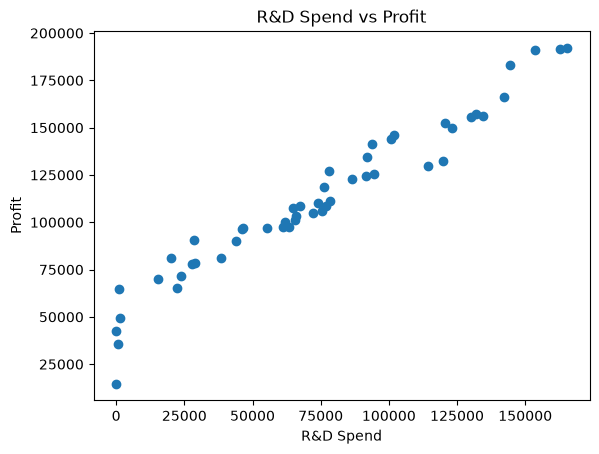

In [34]:
plt.scatter(df["R&D Spend"], df["Profit"])

plt.xlabel("R&D Spend")
plt.ylabel("Profit")
plt.title("R&D Spend vs Profit")

plt.show()

In [35]:
df["R&D Spend"].corr(df["Profit"])

np.float64(0.9729004656594832)

In [36]:
import numpy as np

In [37]:
slope, intercept = np.polyfit(df["R&D Spend"], df["Profit"], 1)

print("Slope:", slope)
print("Intercept:", intercept)

Slope: 0.8542913709388094
Intercept: 49032.89914125208


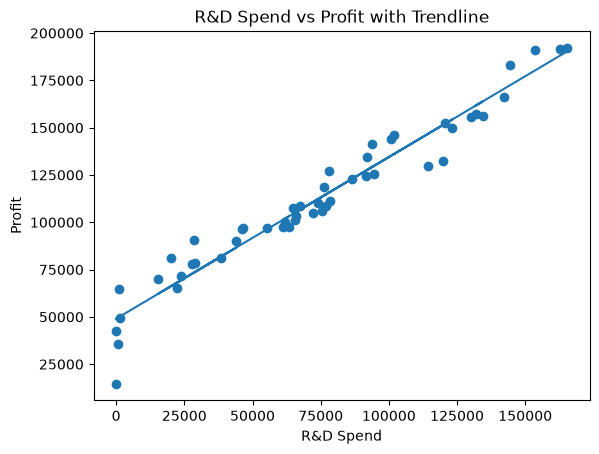

In [38]:
x = df["R&D Spend"]

y_pred = slope * x + intercept

plt.scatter(df["R&D Spend"], df["Profit"])
plt.plot(x, y_pred)

plt.xlabel("R&D Spend")
plt.ylabel("Profit")
plt.title("R&D Spend vs Profit with Trendline")

plt.show()

In [39]:
r_squared = np.corrcoef(df["R&D Spend"], df["Profit"])[0, 1] ** 2

print("R²:", r_squared)

R²: 0.9465353160804392


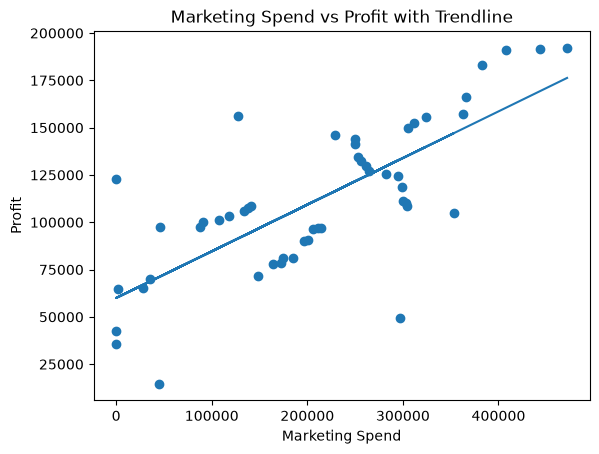

Slope: 0.24645926444976787
Intercept: 60003.54881577171


In [40]:
x = df["Marketing Spend"]
y = df["Profit"]

slope_m, intercept_m = np.polyfit(x, y, 1)
y_pred_m = slope_m * x + intercept_m

plt.scatter(x, y)
plt.plot(x, y_pred_m)

plt.xlabel("Marketing Spend")
plt.ylabel("Profit")
plt.title("Marketing Spend vs Profit with Trendline")

plt.show()

print("Slope:", slope_m)
print("Intercept:", intercept_m)

In [41]:
r_squared_m = np.corrcoef(
    df["Marketing Spend"],
    df["Profit"]
)[0, 1] ** 2

print("Marketing R²:", r_squared_m)

Marketing R²: 0.5591535746115516


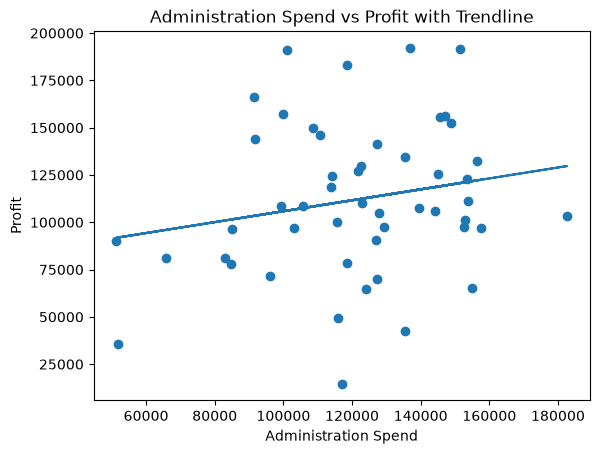

Slope: 0.288749202355226
Intercept: 76974.47130541764


In [42]:
x = df["Administration"]
y = df["Profit"]

slope_a, intercept_a = np.polyfit(x, y, 1)
y_pred_a = slope_a * x + intercept_a

plt.scatter(x, y)
plt.plot(x, y_pred_a)

plt.xlabel("Administration Spend")
plt.ylabel("Profit")
plt.title("Administration Spend vs Profit with Trendline")

plt.show()

print("Slope:", slope_a)
print("Intercept:", intercept_a)

In [43]:
r_squared_a = np.corrcoef(
    df["Administration"],
    df["Profit"]
)[0, 1] ** 2

print("Administration R²:", r_squared_a)

Administration R²: 0.04028714077757225


Markdown
## 2. Exploratory Data Analysis (EDA)

### 2.1 Dataset Overview
### 2.2 Data Quality Checks
### 2.3 Descriptive Statistics
### 2.4 Correlation Analysis
### 2.5 Simple Linear Regression

In [1]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

In [4]:
X = df[["R&D Spend", "Administration", "Marketing Spend"]]
y = df["Profit"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (50, 3)
Target shape: (50,)


In [3]:
import pandas as pd

df = pd.read_csv("../Data/raw data/50_Startups.csv")

print(df.shape)

(50, 5)


In [5]:
X = df[["R&D Spend", "Administration", "Marketing Spend"]]
y = df["Profit"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (50, 3)
Target shape: (50,)


In [6]:
model = LinearRegression()
model.fit(X, y)

print("Model trained successfully!")
print("Intercept:", model.intercept_)
print("R&D coefficient:", model.coef_[0])
print("Administration coefficient:", model.coef_[1])
print("Marketing coefficient:", model.coef_[2])

Model trained successfully!
Intercept: 50122.19298986524
R&D coefficient: 0.8057150499157437
Administration coefficient: -0.02681596839475075
Marketing coefficient: 0.027228064800818817


In [7]:
y_pred = model.predict(X)

r2 = r2_score(y, y_pred)
mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)

print("R²:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

R²: 0.9507459940683246
MAE: 6471.4503961048085
MSE: 78417126.01913083
RMSE: 8855.34448901514


In [8]:
new_startups = pd.DataFrame({
    "R&D Spend": [21892.92, 23940.93],
    "Administration": [81910.77, 96489.63],
    "Marketing Spend": [164270.70, 137001.10]
})

predicted_profit = model.predict(new_startups)

new_startups["Predicted Profit"] = predicted_profit

new_startups

,R&D Spend,Administration,Marketing Spend,Predicted Profit
0,21892.92,81910.77,164270.7,70037.904765
1,23940.93,96489.63,137001.1,70554.572560
